# Notebook 2: Weather, Holidays and Feature Engineering
This notebook adds the two external data sources required by the brief (Dhanbad weather and Dhanbad/Jharkhand holidays), studies how they relate to the load, and builds the feature table used to train the model.

## 1. Weather Data for Dhanbad (Open-Meteo)
We fetch hourly historical weather for Dhanbad, Jharkhand (23.80 N, 86.43 E) for 2017 from the free Open-Meteo archive API: temperature, relative humidity, cloud cover and wind speed. The result is saved to disk so the notebook can be re-run without internet.

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://archive-api.open-meteo.com/v1/archive"
params = {
    "latitude": 23.80,
    "longitude": 86.43,
    "start_date": "2017-01-01",
    "end_date": "2017-12-30",
    "hourly": "temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m",
    "timezone": "Asia/Kolkata",
}
cache_file = "data/weather_dhanbad_2017_hourly.csv"

if os.path.exists(cache_file):
    weather_raw = pd.read_csv(cache_file)
    print("Loaded the saved weather file")
else:
    response = requests.get(url, params=params, timeout=60)
    print("Status:", response.status_code)
    response.raise_for_status()
    weather_raw = pd.DataFrame(response.json()["hourly"])
    weather_raw.to_csv(cache_file, index=False)
    print("Downloaded and saved the weather file")

print(weather_raw.shape)
weather_raw.head()

Status: 200
Downloaded and saved the weather file
(8736, 5)


,time,temperature_2m,relative_humidity_2m,cloud_cover,wind_speed_10m
0,2017-01-01T00:00,14.8,89,18,6.8
1,2017-01-01T01:00,14.5,92,23,6.4
2,2017-01-01T02:00,14.3,94,23,5.6
3,2017-01-01T03:00,14.2,95,21,6.2
4,2017-01-01T04:00,13.9,96,7,5.4


## 2. Weather Cleaning and Alignment
We rename the columns, check completeness and plausibility, and convert the hourly weather to the same 30-minute grid as the load (linear interpolation, since weather changes smoothly).

In [3]:
weather = weather_raw.rename(columns={
    "time": "Datetime",
    "temperature_2m": "temp_c",
    "relative_humidity_2m": "humidity_pct",
    "cloud_cover": "cloud_cover_pct",
    "wind_speed_10m": "wind_kmh",
})
weather["Datetime"] = pd.to_datetime(weather["Datetime"])
weather = weather.set_index("Datetime")

print("Start:", weather.index.min(), "| End:", weather.index.max())
print("Missing hours:", len(pd.date_range(weather.index.min(), weather.index.max(), freq="h")) - len(weather))
print()
print("Missing values:")
print(weather.isnull().sum())
print()
print(weather.describe().round(1))

Start: 2017-01-01 00:00:00 | End: 2017-12-30 23:00:00
Missing hours: 0

Missing values:
temp_c             0
humidity_pct       0
cloud_cover_pct    0
wind_kmh           0
dtype: int64

       temp_c  humidity_pct  cloud_cover_pct  wind_kmh
count  8736.0        8736.0           8736.0    8736.0
mean     25.5          69.5             44.0       8.2
std       5.9          22.0             42.7       4.2
min       7.7           8.0              0.0       0.0
25%      22.0          54.0              0.0       5.4
50%      26.1          75.0             30.0       7.6
75%      28.9          88.0             96.0      10.5
max      41.4         100.0            100.0      32.8


In [4]:
weather30 = weather.resample("30min").interpolate("time")
weather30 = weather30.reindex(pd.date_range("2017-01-01 00:00", "2017-12-30 23:30", freq="30min"))
weather30.index.name = "Datetime"
weather30 = weather30.interpolate("time").ffill()

print("Shape:", weather30.shape, "| Missing values:", weather30.isnull().sum().sum())
weather30.head()

Shape: (17472, 4) | Missing values: 0


,temp_c,humidity_pct,cloud_cover_pct,wind_kmh
Datetime,,,,
2017-01-01 00:00:00,14.80,89.0,18.0,6.8
2017-01-01 00:30:00,14.65,90.5,20.5,6.6
2017-01-01 01:00:00,14.50,92.0,23.0,6.4
2017-01-01 01:30:00,14.40,93.0,23.0,6.0
2017-01-01 02:00:00,14.30,94.0,23.0,5.6


## 3. Weather EDA
We look at the weather over the year, compare it with the temperature column that came with the load file, and study how weather relates to the load.

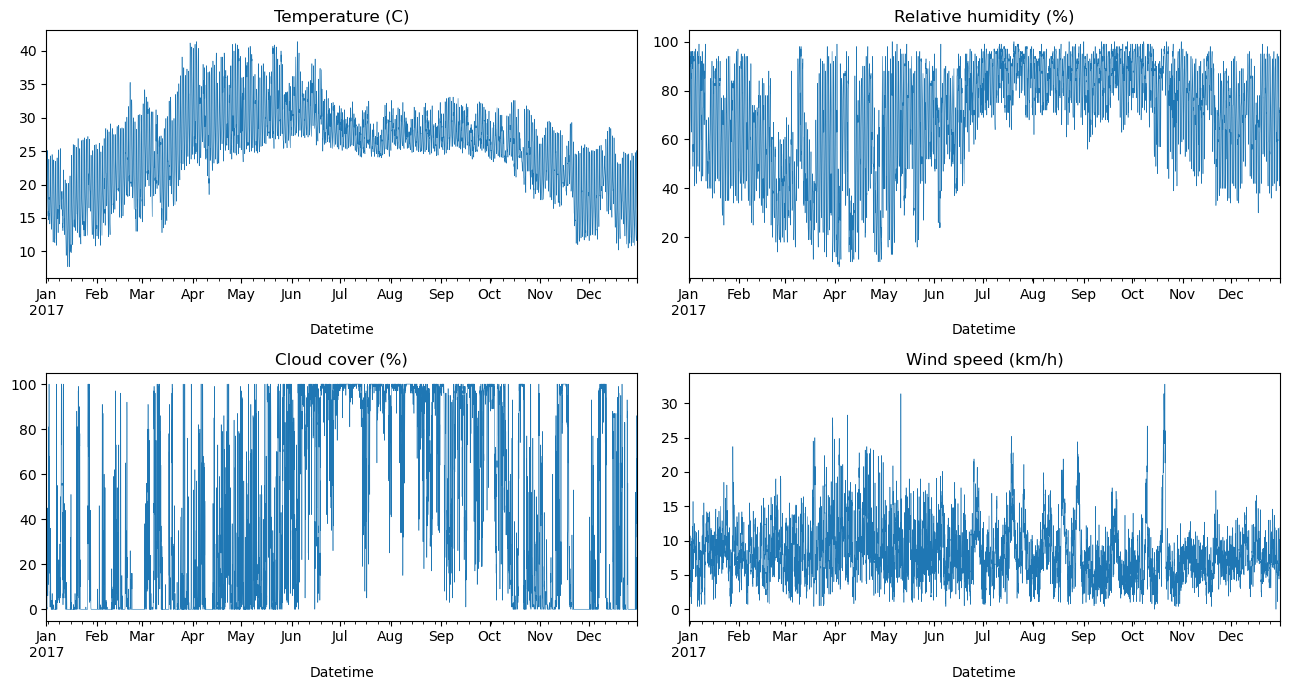

          temp_c  humidity_pct  cloud_cover_pct  wind_kmh
Datetime                                                 
1           18.0          66.4             15.1       8.3
2           21.8          51.8              6.7       8.2
3           25.5          48.4             16.4       8.8
4           30.6          48.1             16.9      10.4
5           30.9          64.9             34.4       8.9
6           30.3          72.2             79.4       8.8
7           27.0          87.4             92.8       8.3
8           27.4          85.9             88.9       8.9
9           27.7          85.6             77.0       6.0
10          25.5          82.7             47.1       7.4
11          21.3          71.0             23.0       7.1
12          19.0          68.2             27.3       7.8


In [5]:
load = pd.read_csv("data/load_clean_30min.csv", index_col="Datetime", parse_dates=True)

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
weather30["temp_c"].plot(ax=axes[0, 0], linewidth=0.4, title="Temperature (C)")
weather30["humidity_pct"].plot(ax=axes[0, 1], linewidth=0.4, title="Relative humidity (%)")
weather30["cloud_cover_pct"].plot(ax=axes[1, 0], linewidth=0.4, title="Cloud cover (%)")
weather30["wind_kmh"].plot(ax=axes[1, 1], linewidth=0.4, title="Wind speed (km/h)")
plt.tight_layout()
plt.show()

monthly_weather = weather30.groupby(weather30.index.month).mean().round(1)
print(monthly_weather)

In [6]:
raw = pd.read_csv("data/Utility_consumption.csv")
d1 = pd.to_datetime(raw["Datetime"], format="%m-%d-%Y %H:%M", errors="coerce")
d2 = pd.to_datetime(raw["Datetime"], format="%m/%d/%Y %H:%M", errors="coerce")
raw["Datetime"] = d1.fillna(d2)
file_temp = raw.set_index("Datetime")["Temperature"].resample("30min").mean()

comp = pd.DataFrame({"file_temp": file_temp, "dhanbad_temp": weather30["temp_c"]}).dropna()
print("Mean temperature in the load file :", round(comp["file_temp"].mean(), 1), "C")
print("Mean temperature from Dhanbad API :", round(comp["dhanbad_temp"].mean(), 1), "C")
print("Correlation between the two       :", round(comp["file_temp"].corr(comp["dhanbad_temp"]), 2))

Mean temperature in the load file : 18.8 C
Mean temperature from Dhanbad API : 25.5 C
Correlation between the two       : 0.56


Total_Load         1.00
temp_c             0.25
humidity_pct       0.01
cloud_cover_pct    0.30
wind_kmh           0.15
Name: Total_Load, dtype: float64


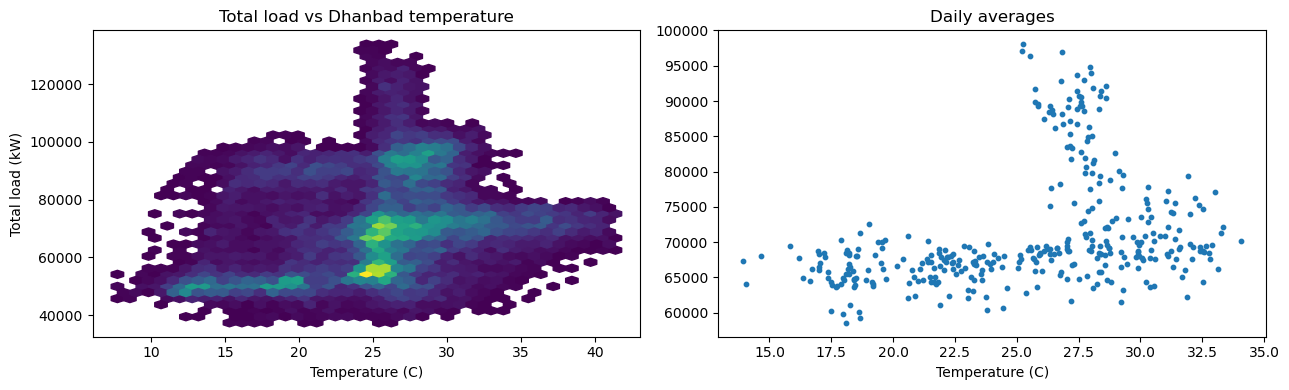

In [7]:
data = load[["Total_Load"]].join(weather30)

print(data.corr().round(2)["Total_Load"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hexbin(data["temp_c"], data["Total_Load"], gridsize=40, cmap="viridis", mincnt=1)
axes[0].set_title("Total load vs Dhanbad temperature")
axes[0].set_xlabel("Temperature (C)")
axes[0].set_ylabel("Total load (kW)")
daily = data.resample("D").mean()
axes[1].scatter(daily["temp_c"], daily["Total_Load"], s=10)
axes[1].set_title("Daily averages")
axes[1].set_xlabel("Temperature (C)")
plt.tight_layout()
plt.show()

**Observation:** Dhanbad is warmer than the location of the load file (mean 25.5 C vs 18.8 C), and the two temperature series are only moderately correlated (0.56), so the temperature column shipped with the load file cannot stand in for Dhanbad weather. Dhanbad is hottest in April-June (about 31 C) and has a humid, cloudy monsoon from July to September. The relationship between weather and load is weak (correlation 0.25 with temperature, 0.30 with cloud cover, 0.15 with wind, about 0 with humidity). The load peaks in July-August, which are not Dhanbad's hottest months, so the cloud cover correlation reflects the monsoon timing rather than a real effect. Weather is therefore treated as a secondary predictor.

## 4. Localized Holidays: Dhanbad / Jharkhand (2017)
A generic national calendar is not enough, so we compiled a list for Dhanbad: national holidays, major festivals observed in the region (Holi, Durga Puja, Diwali, Chhath), Jharkhand tribal festivals (Sarhul, Karma, Tusu, Foundation Day) and industrial/coal-belt holidays (Labour Day, Vishwakarma Puja). Sources: Jharkhand state holiday lists (officeholidays.com), state notifications and the festival calendar. Dates of lunar festivals must be re-checked each year.

In [8]:
holidays = pd.DataFrame([
    ("2017-01-14", "Makar Sankranti / Tusu Parab", "tribal"),
    ("2017-01-26", "Republic Day", "national"),
    ("2017-02-01", "Saraswati Puja", "festival"),
    ("2017-02-24", "Maha Shivratri", "festival"),
    ("2017-03-12", "Holika Dahan", "festival"),
    ("2017-03-13", "Holi", "festival"),
    ("2017-03-30", "Sarhul", "tribal"),
    ("2017-04-05", "Ram Navami", "festival"),
    ("2017-04-09", "Mahavir Jayanti", "festival"),
    ("2017-04-14", "Good Friday", "festival"),
    ("2017-05-01", "Labour Day (Coal belt)", "industrial"),
    ("2017-05-10", "Buddha Purnima", "festival"),
    ("2017-06-26", "Eid-ul-Fitr", "festival"),
    ("2017-08-14", "Janmashtami", "festival"),
    ("2017-08-15", "Independence Day", "national"),
    ("2017-09-02", "Bakrid", "festival"),
    ("2017-09-03", "Karma Puja", "tribal"),
    ("2017-09-17", "Vishwakarma Puja", "industrial"),
    ("2017-09-27", "Durga Puja - Maha Saptami", "festival"),
    ("2017-09-28", "Durga Puja - Maha Ashtami", "festival"),
    ("2017-09-29", "Durga Puja - Maha Navami", "festival"),
    ("2017-09-30", "Dussehra", "festival"),
    ("2017-10-01", "Muharram", "festival"),
    ("2017-10-02", "Gandhi Jayanti", "national"),
    ("2017-10-19", "Diwali / Kali Puja", "festival"),
    ("2017-10-20", "Govardhan Puja", "festival"),
    ("2017-10-24", "Chhath Puja - Nahay Khay", "festival"),
    ("2017-10-25", "Chhath Puja - Kharna", "festival"),
    ("2017-10-26", "Chhath Puja - Sandhya Arghya", "festival"),
    ("2017-10-27", "Chhath Puja - Usha Arghya", "festival"),
    ("2017-11-04", "Guru Nanak Jayanti", "festival"),
    ("2017-11-15", "Jharkhand Foundation Day", "tribal"),
    ("2017-12-02", "Eid-e-Milad", "festival"),
    ("2017-12-25", "Christmas", "national"),
], columns=["date", "holiday", "category"])

holidays["date"] = pd.to_datetime(holidays["date"])
holidays["weekday"] = holidays["date"].dt.day_name()
holidays.to_csv("data/holidays_dhanbad_2017.csv", index=False)

print("Number of holidays:", len(holidays))
print(holidays["category"].value_counts())
holidays.head(10)

Number of holidays: 34
category
festival      24
tribal         4
national       4
industrial     2
Name: count, dtype: int64


,date,holiday,category,weekday
0,2017-01-14,Makar Sankranti / Tusu Parab,tribal,Saturday
1,2017-01-26,Republic Day,national,Thursday
2,2017-02-01,Saraswati Puja,festival,Wednesday
3,2017-02-24,Maha Shivratri,festival,Friday
4,2017-03-12,Holika Dahan,festival,Sunday
5,2017-03-13,Holi,festival,Monday
6,2017-03-30,Sarhul,tribal,Thursday
7,2017-04-05,Ram Navami,festival,Wednesday
8,2017-04-09,Mahavir Jayanti,festival,Sunday
9,2017-04-14,Good Friday,festival,Friday


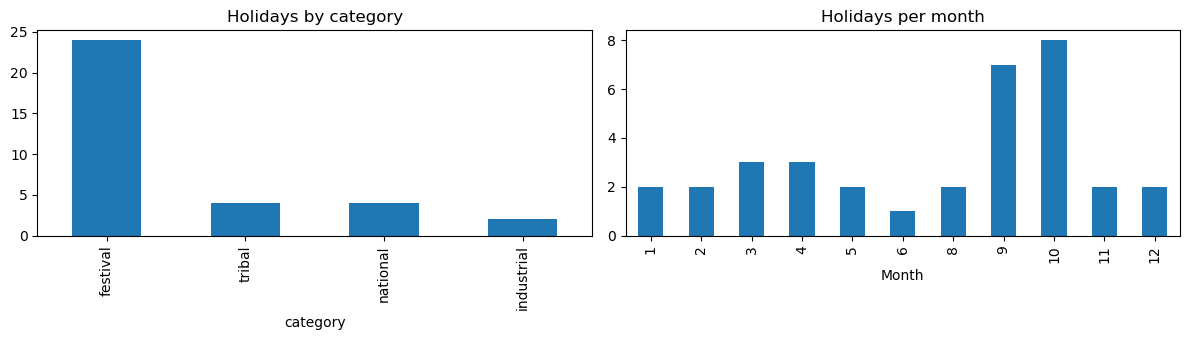

On a weekend: 10 of 34


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
holidays["category"].value_counts().plot(kind="bar", ax=axes[0], title="Holidays by category")
holidays.groupby(holidays["date"].dt.month).size().plot(kind="bar", ax=axes[1], title="Holidays per month")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

print("On a weekend:", holidays["weekday"].isin(["Saturday", "Sunday"]).sum(), "of", len(holidays))

## 5. Do Holidays Change the Load?
For each holiday we compare the daily average load with the average of normal (non-holiday) days of the same type (weekday or weekend) within 15 days. A ratio below 1 means lower demand than normal.

In [18]:
daily_load = load["Total_Load"].resample("D").mean()
hol_dates = set(holidays["date"])

rows = []
for d, name in zip(holidays["date"], holidays["holiday"]):
    if d not in daily_load.index:
        continue
    # compare with normal days of the same type (weekend vs weekday), within 15 days
    is_weekend = d.dayofweek >= 5
    same_type = (daily_load.index.dayofweek >= 5) == is_weekend
    window = daily_load[(abs((daily_load.index - d).days) <= 15)
                        & (~daily_load.index.isin(hol_dates))
                        & same_type]
    rows.append({"holiday": name, "date": d.date(),
                 "ratio_to_normal": round(daily_load[d] / window.mean(), 3)})

impact = pd.DataFrame(rows).sort_values("ratio_to_normal")
print(impact.to_string(index=False))
print()
print("Average ratio over all holidays:", round(impact["ratio_to_normal"].mean(), 3))
print("Median ratio                   :", round(impact["ratio_to_normal"].median(), 3))

                     holiday       date  ratio_to_normal
                      Bakrid 2017-09-02            0.847
                  Karma Puja 2017-09-03            0.860
                 Eid-ul-Fitr 2017-06-26            0.910
      Labour Day (Coal belt) 2017-05-01            0.930
                    Muharram 2017-10-01            0.950
            Vishwakarma Puja 2017-09-17            0.952
                 Eid-e-Milad 2017-12-02            0.971
             Mahavir Jayanti 2017-04-09            0.982
                 Janmashtami 2017-08-14            0.983
                    Dussehra 2017-09-30            0.984
              Gandhi Jayanti 2017-10-02            0.984
              Govardhan Puja 2017-10-20            0.986
              Maha Shivratri 2017-02-24            0.989
   Chhath Puja - Usha Arghya 2017-10-27            0.990
                 Good Friday 2017-04-14            0.990
              Saraswati Puja 2017-02-01            0.991
                Holika Dahan 20

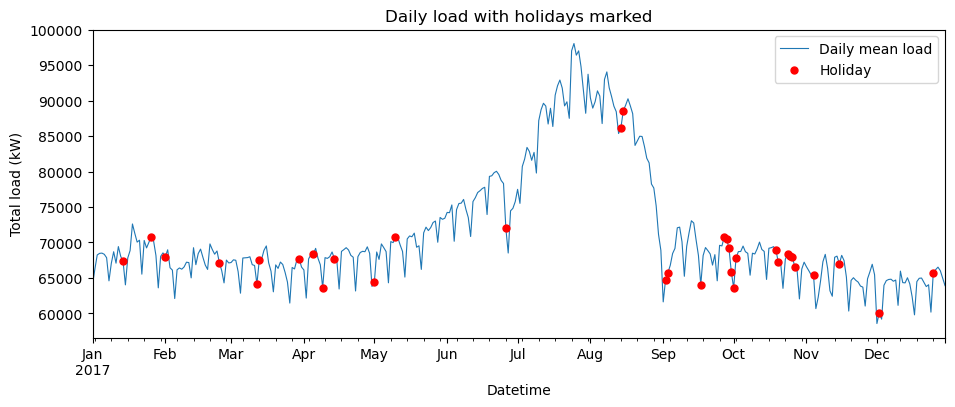

In [11]:
fig, ax = plt.subplots(figsize=(11, 4))
daily_load.plot(ax=ax, linewidth=0.8, label="Daily mean load")
hol_load = daily_load[daily_load.index.isin(hol_dates)]
ax.scatter(hol_load.index, hol_load.values, color="red", s=25, zorder=3, label="Holiday")
ax.set_title("Daily load with holidays marked")
ax.set_ylabel("Total load (kW)")
ax.legend()
plt.show()

**Observation:** On average a holiday changes the daily load only slightly (mean ratio 0.986, median 0.997 compared with normal days of the same type). The effect is concentrated in specific days: Bakrid (0.85), Karma Puja (0.86), Eid-ul-Fitr (0.91) and Labour Day (0.93) show a clear dip of 7-15%, while the large Hindu festivals (Diwali, Durga Puja, Chhath) are close to normal. We therefore keep holiday flags (by category) as features and rely on a tree-based model, which can learn such selective effects. Dates of lunar festivals can differ by a day between sources (for example Karma Puja), so they should be re-verified each year.

## 6. Combining Load and Weather
The three feeders, Total_Load and the Dhanbad weather are joined on the 30-minute timestamp.

In [12]:
df = load[["F1_132KV_PowerConsumption", "F2_132KV_PowerConsumption", "F3_132KV_PowerConsumption", "Total_Load"]].copy()
df.columns = ["F1", "F2", "F3", "Total_Load"]
df = df.join(weather30)

print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (17472, 8)
Missing values: 0


,F1,F2,F3,Total_Load,temp_c,humidity_pct,cloud_cover_pct,wind_kmh
Datetime,,,,,,,,
2017-01-01 00:00:00,30999.493670,18170.212767,20013.493977,69183.200413,14.80,89.0,18.0,6.8
2017-01-01 00:30:00,27396.455697,17883.282673,18490.602410,63770.340780,14.65,90.5,20.5,6.6
2017-01-01 01:00:00,25407.594937,16627.355623,17476.626507,59511.577067,14.50,92.0,23.0,6.4
2017-01-01 01:30:00,23906.835443,15529.483283,16609.156627,56045.475353,14.40,93.0,23.0,6.0
2017-01-01 02:00:00,22474.936707,14767.173253,15870.843373,53112.953333,14.30,94.0,23.0,5.6


## 7. Feature Engineering
Features are built from what the EDA showed: a strong daily cycle, a seasonal swing, a weekly effect, weather dependence, holiday effects and very high autocorrelation at 24 hours and 7 days.

In [13]:
idx = df.index

df["block"] = idx.hour * 2 + idx.minute // 30
df["dayofweek"] = idx.dayofweek
df["month"] = idx.month
df["dayofyear"] = idx.dayofyear
df["is_weekend"] = (idx.dayofweek >= 5).astype(int)

df["block_sin"] = np.sin(2 * np.pi * df["block"] / 48)
df["block_cos"] = np.cos(2 * np.pi * df["block"] / 48)
df["dow_sin"] = np.sin(2 * np.pi * df["dayofweek"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["dayofweek"] / 7)
df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

df[["block", "dayofweek", "month", "is_weekend", "block_sin", "block_cos"]].head()

,block,dayofweek,month,is_weekend,block_sin,block_cos
Datetime,,,,,,
2017-01-01 00:00:00,0,6,1,1,0.000000,1.000000
2017-01-01 00:30:00,1,6,1,1,0.130526,0.991445
2017-01-01 01:00:00,2,6,1,1,0.258819,0.965926
2017-01-01 01:30:00,3,6,1,1,0.382683,0.923880
2017-01-01 02:00:00,4,6,1,1,0.500000,0.866025


In [14]:
dates = pd.Series(idx.normalize(), index=idx)

df["is_holiday"] = dates.isin(holidays["date"]).astype(int)
for cat in ["national", "festival", "tribal", "industrial"]:
    cat_dates = holidays.loc[holidays["category"] == cat, "date"]
    df["is_" + cat] = dates.isin(cat_dates).astype(int)

df["is_day_before_holiday"] = dates.isin(holidays["date"] - pd.Timedelta(days=1)).astype(int)
df["is_day_after_holiday"] = dates.isin(holidays["date"] + pd.Timedelta(days=1)).astype(int)

print(df[["is_holiday", "is_national", "is_festival", "is_tribal", "is_industrial",
          "is_day_before_holiday", "is_day_after_holiday"]].sum() // 48)

is_holiday               34
is_national               4
is_festival              24
is_tribal                 4
is_industrial             2
is_day_before_holiday    34
is_day_after_holiday     34
dtype: int64


In [15]:
df["temp_roll_3h"] = df["temp_c"].rolling(6, min_periods=1).mean()
df["temp_roll_24h"] = df["temp_c"].rolling(48, min_periods=1).mean()
df["temp_x_humidity"] = df["temp_c"] * df["humidity_pct"] / 100

df[["temp_c", "temp_roll_3h", "temp_roll_24h", "temp_x_humidity"]].describe().round(1)

,temp_c,temp_roll_3h,temp_roll_24h,temp_x_humidity
count,17472.0,17472.0,17472.0,17472.0
mean,25.5,25.5,25.5,17.2
std,5.8,5.8,4.6,6.0
min,7.7,8.2,13.7,3.3
25%,22.0,22.1,21.9,11.7
50%,26.1,26.1,26.6,18.2
75%,28.9,28.9,28.7,23.0
max,41.4,41.1,34.1,26.9


In [19]:
# Lag features: past load values used to predict the current block.
# The smallest lag is 48 blocks (24 hours): for a 24-hour-ahead forecast,
# anything newer would not be known at forecast time (data leakage).
df["lag_48"] = df["Total_Load"].shift(48)      # same time yesterday
df["lag_96"] = df["Total_Load"].shift(96)      # same time two days ago
df["lag_336"] = df["Total_Load"].shift(336)    # same time last week

# Average load of the previous 24 hours, also shifted by 24 hours
df["mean_prev_24h"] = df["Total_Load"].shift(48).rolling(48).mean()

print("Rows with missing lag values:", df["lag_336"].isnull().sum())
df[["Total_Load", "lag_48", "lag_96", "lag_336", "mean_prev_24h"]].iloc[336:340]

Rows with missing lag values: 336


,Total_Load,lag_48,lag_96,lag_336,mean_prev_24h
Datetime,,,,,
2017-01-08 00:00:00,64181.578557,64574.087063,64522.302280,69183.200413,68334.166444
2017-01-08 00:30:00,59672.437197,60201.143030,60260.378950,63770.340780,68332.932363
2017-01-08 01:00:00,56362.712693,56377.789120,56274.789170,59511.577067,68335.078195
2017-01-08 01:30:00,54018.765047,53795.063187,53711.494757,56045.475353,68336.819204


## 8. Final Feature Table
The first week has no 7-day lag, so those rows are dropped. The table is saved for model training in the next notebook.

In [17]:
features_df = df.dropna().copy()
features_df.to_csv("data/features_30min.csv")

print("Rows before:", len(df), "| after dropping the first week:", len(features_df))
print("Number of columns:", features_df.shape[1])
print("Period:", features_df.index.min(), "to", features_df.index.max())
print(list(features_df.columns))

Rows before: 17472 | after dropping the first week: 17136
Number of columns: 33
Period: 2017-01-08 00:00:00 to 2017-12-30 23:30:00
['F1', 'F2', 'F3', 'Total_Load', 'temp_c', 'humidity_pct', 'cloud_cover_pct', 'wind_kmh', 'block', 'dayofweek', 'month', 'dayofyear', 'is_weekend', 'block_sin', 'block_cos', 'dow_sin', 'dow_cos', 'month_sin', 'month_cos', 'is_holiday', 'is_national', 'is_festival', 'is_tribal', 'is_industrial', 'is_day_before_holiday', 'is_day_after_holiday', 'temp_roll_3h', 'temp_roll_24h', 'temp_x_humidity', 'lag_48', 'lag_96', 'lag_336', 'mean_prev_24h']


## 9. Summary
- Dhanbad weather (temperature, humidity, cloud cover, wind speed) was fetched from Open-Meteo, validated and aligned to the 30-minute load grid.
- A localized holiday calendar for Dhanbad/Jharkhand (34 days, four categories) was compiled; its effect on the daily load is modest on average but strong for specific festivals (e.g. Bakrid, Karma Puja, Eid, Labour Day).
- Features: calendar (cyclical), holiday flags, weather and rolling temperature, and load lags of 24 h, 48 h and 7 days (never shorter than 24 h, to avoid leakage in a 24-hour-ahead forecast).
- The feature table is saved to data/features_30min.csv for modelling.
-  The weather shows only a weak relationship with this load (correlation up to 0.30), and the load peaks in July-August while Dhanbad is hottest in April-June. Weather is therefore treated as a secondary feature, and lags and calendar features are expected to carry most of the predictive power.